# 2 · IMERG half-hourly → 3- or 6-hourly rainfall at stations

Reads the files downloaded by notebook 1 and writes one CSV per period:

| station_id | name | lat | lon | datetime_end_utc | imerg_mm |
|---|---|---|---|---|---|

* `datetime_end_utc` is the **end** of the accumulation period (06:00 = 00:00–06:00 UTC).
* `imerg_mm` is the rain total in mm. With `WINDOW = 3` it is the mean of the 3 × 3 IMERG cells
  (0.1°, ≈ 30 km) centred on the station; `WINDOW = 1` uses only the nearest cell.
* A period with a missing file is left empty and the file is listed.

In [1]:
# Cell 1 – settings
import os, sys
sys.path.insert(0, os.path.abspath('..'))   # so the notebook can import imerg_utils.py from the repo root
import pandas as pd
import imerg_utils as iu

STATIONS_CSV     = '../examples/stations_bangladesh.csv'  # needs columns station_id, name, lat, lon
PERIODS_CSV      = '../examples/periods.csv'
HOURS            = 6     # 3 or 6 – must match notebook 1
UTC_OFFSET_HOURS = 0     # must match notebook 1
WINDOW           = 3     # 1 = nearest cell, 3 = 3x3 mean, 5 = 5x5 mean
DATA_DIR         = '../data/imerg'
OUTPUT_DIR       = '../output'

os.makedirs(OUTPUT_DIR, exist_ok=True)
stations = iu.load_stations(STATIONS_CSV)
periods  = pd.read_csv(PERIODS_CSV)
files    = iu.index_imerg_files(DATA_DIR)
print(f'{len(stations)} stations, {len(periods)} periods, {len(files)} IMERG files')
if files:
    print('files from', min(files), 'to', max(files))

41 stations, 1 periods, 60 IMERG files
files from 2024-07-19 00:00:00 to 2024-07-20 05:30:00


In [2]:
# Cell 2 – compute and save
results = {}
for p in periods.itertuples():
    bins = iu.make_bin_ends(p.start, p.end, HOURS, UTC_OFFSET_HOURS)
    table, missing = iu.station_accumulation(files, stations, bins, HOURS, WINDOW, UTC_OFFSET_HOURS)
    out = os.path.join(OUTPUT_DIR, f'imerg_{HOURS}h_{p.name}.csv')
    table.to_csv(out, index=False)
    results[p.name] = table
    print(f'{p.name}: {len(table)} rows -> {out}  ({table.imerg_mm.isna().sum()} empty)')
    for t in missing:
        print('    missing file starting', t.strftime('%Y-%m-%d %H:%M'))

demo_2024_07_19: 205 rows -> ../output\imerg_6h_demo_2024_07_19.csv  (0 empty)


In [3]:
# Cell 3 – look at the first period: stations x time
first = next(iter(results.values()))
first.pivot(index='name', columns='datetime_end_utc', values='imerg_mm')

datetime_end_utc,2024-07-19 06:00:00,2024-07-19 12:00:00,2024-07-19 18:00:00,2024-07-20 00:00:00,2024-07-20 06:00:00
name,,,,,
Ambagan(CTG),0.266,0.130,2.023,2.230,1.027
Badalgachi,1.983,0.149,0.026,0.779,0.207
Bagabari,0.000,0.000,0.358,1.265,1.498
Barishal,0.283,0.190,1.499,0.769,0.000
Bhola,0.000,0.137,1.249,0.383,1.529
Bogra,3.108,0.000,0.077,1.356,1.207
Chattogram,0.303,0.089,1.515,2.401,1.284
Chuadanga,0.000,0.000,0.000,0.000,0.045
Comilla,0.222,0.053,7.791,0.000,1.220


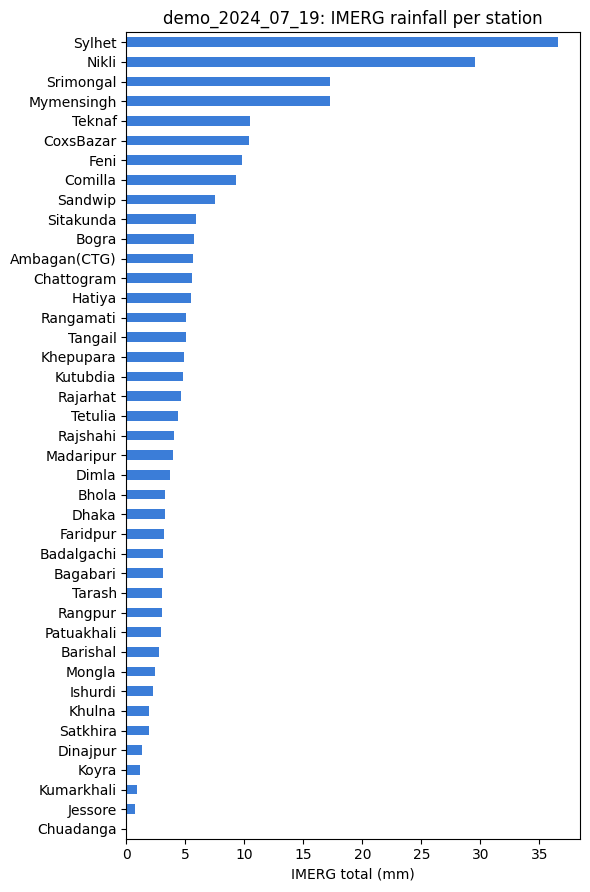

In [4]:
# Cell 4 – (optional) total rain per station for the first period
import matplotlib.pyplot as plt
tot = first.groupby('name').imerg_mm.sum().sort_values()
ax = tot.plot.barh(figsize=(6, max(3, len(tot) * 0.22)), color='#3b7dd8')
ax.set_xlabel('IMERG total (mm)'); ax.set_ylabel('')
ax.set_title(f'{next(iter(results))}: IMERG rainfall per station')
plt.tight_layout(); plt.show()